In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import scipy
import mdtraj as md
import MDAnalysis
from typing import Dict, Tuple
import os
import seaborn as sns

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "Times New Roman",
    "font.serif": ["Arial"],  # or other preferred serif font
    "mathtext.fontset": "cm",            # Computer Modern for math text
    "text.usetex": False,                 # Use LaTeX for text rendering]
    "pdf.fonttype": 42,                 # Use LaTeX for text rendering

    # Figure
    "figure.figsize": (6, 4),            # width, height in inches
    "figure.dpi": 150,                   # medium resolution

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,                   # optional, remove if you want no grid
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

def find_xtc_filenames(path_to_dir, suffix=".xtc"):
    filenames = os.listdir(path_to_dir)
    return [filename for filename in filenames if filename.endswith(suffix)]

# --- Utility functions ---
def RMSE(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)
    return np.sqrt(np.mean((actual - predicted)**2))

def noe_rmse(exp, avg):
    """
    Compute fraction of NOE violations and RMSE of violations.
    RMSE is averaged over all restraints; violations outside bounds
    contribute positive values, in-bound distances contribute 0.

    Parameters
    ----------
    exp : np.ndarray, shape (n_restraints, 3)
        Experimental NOE info: [avg_dist, lower_bound, upper_bound]
    avg : np.ndarray, shape (n_restraints,)
        Simulated average distances for the same restraints

    Returns
    -------
    frac_viol : float
        Fraction of violated NOEs (|violation| > 0)
    rmse : float
        Root-mean-square error over all restraints (0 contribution for in-bounds)
    """

    exp = np.asarray(exp)
    avg = np.asarray(avg)
    assert exp.shape[0] == avg.shape[0], "EXP and AVG must have same number of restraints"

    lower = exp[:, 1]
    upper = exp[:, 2]

    # compute violations
    viol_low = lower - avg   # positive if below lower bound
    viol_up = avg - upper    # positive if above upper bound

    # violation magnitude, zero if inside bounds
    viol = np.where(viol_low > 0, viol_low,
                    np.where(viol_up > 0, viol_up, 0.0))

    n_total = len(avg)
    n_viol = np.count_nonzero(viol)
    frac_viol = n_viol / n_total if n_total > 0 else np.nan

    # RMSE over all restraints (0 for in-bound)
    rmse = np.sqrt(np.mean(viol**2))

    return frac_viol, rmse


def load_pf_data(protein, model_name, ensemble_dir="MD_DATA", exp_dir="EXP_DATA/PF_Nguyen_2018"):
    exp = pd.read_csv(f"../../{exp_dir}/{protein}.csv")
    residues = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/exp_residues.txt")
    priorPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/prior_lnPF.txt"))
    if model_name in ('rewBV2006', 'rewBV2006ang'):
        rewPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/rew_lnPF.txt"))
        stats = pd.read_csv(f"../../{ensemble_dir}/{protein}/{model_name}/stats_df.csv")
        rewdata = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/reweighting_chi2_phi_theta.txt")
    else:
        rewPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_rew_lnPF.txt"))
        stats = pd.read_csv(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_stats_df.csv")
        rewdata = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_reweighting_chi2_phi_theta.txt")
    chi2, phi, thetas = rewdata[0, :], rewdata[1, :], rewdata[2, :]
    idxs = [list(exp["Model_residue"]).index(ele) for ele in residues]
    return exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs

def find_elbow(x, y):
    # Convert to numpy arrays
    x = np.array(x)
    y = np.array(y)

    # Sort x (and y) if needed, but keep track of original indices
    if not np.all(np.diff(x) >= 0):
        idx_sort = np.argsort(x)
        x_sorted = x[idx_sort]
        y_sorted = y[idx_sort]
    else:
        idx_sort = np.arange(len(x))
        x_sorted, y_sorted = x, y

    # Line between first and last point
    p1 = np.array([x_sorted[0], y_sorted[0]])
    p2 = np.array([x_sorted[-1], y_sorted[-1]])
    line_vec = p2 - p1
    line_vec_norm = line_vec / np.linalg.norm(line_vec)

    # Distances from each point to the line
    vec_from_p1 = np.vstack([x_sorted - p1[0], y_sorted - p1[1]]).T
    proj_len = np.dot(vec_from_p1, line_vec_norm)
    proj_point = np.outer(proj_len, line_vec_norm) + p1
    dist = np.linalg.norm(vec_from_p1 - (proj_point - p1), axis=1)

    # Elbow = point with maximum distance
    idx_elbow_sorted = np.argmax(dist)
    idx_elbow_original = idx_sort[idx_elbow_sorted]

    return idx_elbow_original, x[idx_elbow_original], y[idx_elbow_original]

# Function to calculate helical fraction
def helical_fraction(ss_line):
    helix_chars = {'H', 'G', 'I'}
    n_residues = len(ss_line)
    n_helical = sum(1 for c in ss_line if c in helix_chars)
    return n_helical / n_residues

# Function to calculate per-residue helicity per frame
def dssp_to_helicity(dssp_lines):
    """
    Convert DSSP strings into a binary helicity matrix.
    
    Parameters
    ----------
    dssp_lines : list of str
        Each entry corresponds to one frame.
        Each string is the DSSP assignment per residue for that frame.
    
    Returns
    -------
    helicity : np.ndarray
        Array of shape (n_frames, n_residues).
        1 = helix ('H', 'G', 'I'), 0 = non-helix.
    """
    helix_codes = {'H', 'G', 'I'}
    
    n_frames = len(dssp_lines)
    n_residues = len(dssp_lines[0])
    
    helicity = np.zeros((n_frames, n_residues), dtype=int)
    
    for i, line in enumerate(dssp_lines):
        helicity[i, :] = [1 if c in helix_codes else 0 for c in line]
    
    return helicity

def weighted_noe_avg(d, weights):
    """
    Vectorized weighted average for NOE distances with power -6.
    d: (n_frames, n_restraints)
    weights: (n_weights, n_frames)  OR (n_frames,)
    Returns:
        avg_dists: (n_weights, n_restraints) or (n_restraints,)
    """
    d_inv6 = d ** -6  # (n_frames, n_restraints)
    if weights.ndim == 1:
        num = np.dot(weights, d_inv6)
        den = np.sum(weights)
        avg = (num / den) ** (-1 / 6)
        return avg
    else:
        # weights shape (n_weights, n_frames)
        num = np.dot(weights, d_inv6)          # (n_weights, n_restraints)
        den = np.sum(weights, axis=1)[:, None] # (n_weights, 1)
        avg = (num / den) ** (-1 / 6)
        return avg

outpath = './NOE_analyses/'

In [2]:
proteins = ['ACBP', 'ACP', 'CI2', 'GB3', 'HP36', 'Jarastatin', 'lDHFR', 'Lysozyme', 'SAMP1', 'Ubiquitin']

for protein in proteins:
    models = ['rewBV2006', 'rewBV2006ang', 'rewM9', 'rewM9DH', 'rewM9DH_scaled', 
          'rewM10', 'rewM10DH', 'rewM10DH_scaled', 'rewM11', 'rewM11DH', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH', 'rewM12DH_scaled', 'rewM14', 'rewM14DH', 'rewM14DH_scaled']


    traj_names = np.sort(find_xtc_filenames(f'../../MD_DATA/{protein}/'))

    n_models = len(models)
    ncols=4
    fig, axes = plt.subplots(nrows=n_models, ncols=ncols, figsize=(ncols*4., 3.5 * n_models))

    # load NOE data
    for i in range(len(traj_names)):
        if i==0:
            d = np.load(f'../../MD_DATA/{protein}/NOE/d_{traj_names[i][:-4]}.npy')
        else:
            tmpd = np.load(f'../../MD_DATA/{protein}/NOE/d_{traj_names[i][:-4]}.npy')
            d= np.concatenate((d, tmpd), axis=0)

    # experimental data
    EXP = np.loadtxt(f'../../MD_DATA/{protein}/NOE/Exp_NOE_distances.txt')

    # filter distances which are 0
    valid = np.where(np.mean(d, axis=0)>0)[0]
    EXP = EXP[valid]
    d = d[:, valid]




    for i, model in enumerate(models):
        exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs = load_pf_data(protein, model_name=model)
        if model in ('rewBV2006', 'rewBV2006ang'):
            wopt_array = np.load(f"../../MD_DATA/{protein}/{model}/wopt_array.npy")
            wopt = np.load(f"../../MD_DATA/{protein}/{model}/wopt.npy")
        else:
            wopt_array = np.load(f"../../MD_DATA/{protein}/{model}/log_lambda_wopt_array.npy")
            wopt = np.load(f"../../MD_DATA/{protein}/{model}/log_lambda_wopt.npy")

        savedf = pd.DataFrame()
        savedf['Neff'] = phi

        expPF = np.array(exp["PF"][idxs])
        rmse_prior = RMSE(np.log10(expPF), np.log10(priorPF))
        rmse_post = RMSE(np.log10(expPF), np.log10(rewPF))
        r_prior = scipy.stats.pearsonr(np.log10(expPF), np.log10(priorPF))[0]
        r_post = scipy.stats.pearsonr(np.log10(expPF), np.log10(rewPF))[0]

        # calculate RMSE to validation data: only NOE distances that are below lower bound or above upper bound (RMSE=0 for distances that are within the range)
        '''
        validation_diff = []
        for W in wopt_array:
            avg = np.average(d ** -6, axis=0, weights=W) ** (-1 / 6)
            frac_viol, rmse = noe_rmse(EXP, avg)
            validation_diff.append(rmse)
        '''
        avg_matrix = weighted_noe_avg(d, wopt_array)  # shape (n_weights, n_restraints)
        # compute all RMSEs at once
        validation_diff = np.array([noe_rmse(EXP, avg)[1] for avg in avg_matrix])
        savedf['NOE_RMSE'] = validation_diff

        prior_avg = np.mean(d ** -6, axis=0) ** (-1 / 6)
        post_avg = np.average(d ** -6, axis=0, weights=wopt) ** (-1 / 6)
        frac_viol_prior, noe_rmse_prior = noe_rmse(EXP, prior_avg)
        frac_viol_post, noe_rmse_post = noe_rmse(EXP, post_avg)

        # --- Plot 1: neff vs RMSE with validation data ---
        ax = axes[i, 0]
        ax.scatter(phi, validation_diff, c="tab:red")
        ax.set_xlabel("N$_{eff}$"); ax.set_ylabel("RMSE ($\\AA$)")
        ax.set_title(f"{model}")
        ax.set_ylim(0, np.max(np.abs(validation_diff))*1.2 )

        # --- Plot 2: Per-residue PFs ---
        ax = axes[i, 1]
        ax.set_title(f"Prior: RMSE={rmse_prior:.2f}\nPosterior: RMSE={rmse_post:.2f}")
        ax.bar(residues, expPF, color="lightblue", alpha=0.5, label="Exp.")
        ax.scatter(residues, priorPF, color="tab:blue", label="Prior")
        ax.scatter(residues, rewPF, color="tab:red",label="Posterior")
        ax.set_yscale("log")
        ax.set_ylim(0,1e8)
        ax.set_xlabel("Residue"); ax.set_ylabel("PF")

        # --- Plot 3: PF exp vs calc prior and posterior ---
        ax = axes[i, 2]
        ax.set_title(f"Prior: r={r_prior:.2f}\nPosterior: r={r_post:.2f}")
        ax.scatter(expPF, priorPF, color="tab:blue", label="Prior")
        ax.scatter(expPF, rewPF, color="tab:red", label="Posterior")
        ax.plot([-10, 1e10], [-10, 1e10], color='black', linestyle='dashed', linewidth=1)
        ax.set_yscale("log")
        ax.set_xscale("log")
        ax.set_ylim(0,1e8)
        ax.set_xlim(0,1e8)
        ax.set_xlabel("Exp. PF"); ax.set_ylabel("Calc. PF")

        # --- Plot 4: NOE restraints and the avg distance of prior and posterior ---

        ax = axes[i, 3]

        restraint_id = np.arange(EXP.shape[0])

        # prior and posterior RMSE
        ax.set_title(f"Prior: RMSE={noe_rmse_prior:.3f} $\\AA$\nPosterior: RMSE={noe_rmse_post:.3f} $\\AA$")

        # experimental and ensemble averaged values
        asym_err = np.vstack((EXP[:,0]-EXP[:,1], EXP[:,2]-EXP[:,0])) # lower error, upper error
        ax.errorbar(restraint_id, EXP[:,0], yerr=asym_err, color = 'lightblue', fmt='o',capsize = 1, label = 'Exp.', elinewidth=0.5, alpha=0.5)
        ax.scatter(restraint_id, prior_avg, color="tab:blue", label="Prior", zorder=20)
        ax.scatter(restraint_id, post_avg, color="tab:red", label="Posterior", zorder=20)

        ax.set_ylabel('Distance ($\\AA$)')
        ax.set_xlabel('Restraint ID')

        # set legend
        ax.legend(loc='upper right')

        # save validation diff data 
        savedf.to_csv(outpath+f"{protein}_{model}_NOE_validation.csv")
        
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.savefig(outpath+f"{protein}_HDXrew_NOE.png", dpi=200, bbox_inches="tight")
    plt.close()
        
        


/tmp/ipykernel_1705617/85828079.py:84: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,1e8)
/tmp/ipykernel_1705617/85828079.py:95: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,1e8)
/tmp/ipykernel_1705617/85828079.py:96: UserWarning: Attempted to set non-positive left xlim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_xlim(0,1e8)
/tmp/ipykernel_1705617/85828079.py:84: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,1e8)
/tmp/ipykernel_1705617/85828079.py:95: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,1e8)
/tmp/ipykernel_1705617/85828079.py:96: UserWarning: Attempted to set non-positive left xlim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_xlim(0,1

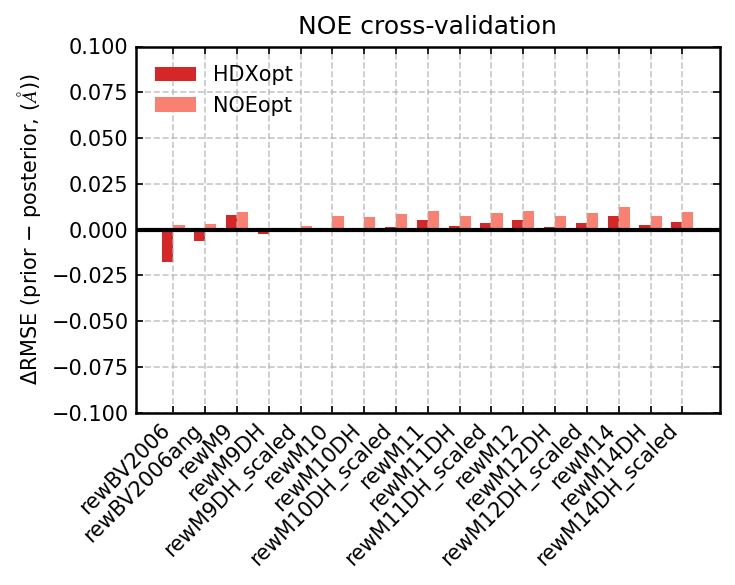

In [3]:
# summary barplot (deltaRMSE prior vs posterior)
# posterior 1 (HDXopt): best HDX fit (final point of the reweighting curve)
# posterior 2 (NOEopt): best validation data fit (minimum point of the reweighting curve - if no improvement this is simply the prior)

proteins = ['ACP', 'CI2', 'GB3', 'HP36', 'Jarastatin', 'lDHFR', 'Lysozyme', 'SAMP1', 'Ubiquitin']
proteins = ['ACBP', 'ACP', 'CI2', 'GB3', 'HP36', 'Jarastatin', 'lDHFR', 'Lysozyme', 'SAMP1', 'Ubiquitin']
models = ['rewBV2006', 'rewBV2006ang', 'rewM9', 'rewM9DH', 'rewM9DH_scaled', 
          'rewM10', 'rewM10DH', 'rewM10DH_scaled', 'rewM11', 'rewM11DH', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH', 'rewM12DH_scaled', 'rewM14', 'rewM14DH', 'rewM14DH_scaled']


mean_diff1 = []
mean_diff2 = []

for model in models:

    prior = []
    post1 = []
    post2 = []

    for protein in proteins:
        dat = pd.read_csv(outpath+f'{protein}_{model}_NOE_validation.csv')

        prior.append(list(dat['NOE_RMSE'])[0])
        post1.append(list(dat['NOE_RMSE'])[-1])
        post2.append(np.min(dat['NOE_RMSE']))

    diff1 = np.array(prior)- np.array(post1)
    diff2 = np.array(prior)- np.array(post2)

    mean_diff1.append(np.mean(diff1))
    mean_diff2.append(np.mean(diff2))

df = pd.DataFrame()
df['Model']=models
df['HDXopt'] = mean_diff1
df['NOEopt'] = mean_diff2





x = np.arange(len(df['Model']))          # positions for models
width = 0.35                             # width of the bars

fig, ax = plt.subplots(figsize=(5,4))

ax.bar(x - width/2, df['HDXopt'], width, label='HDXopt', color = 'tab:red')
ax.bar(x + width/2, df['NOEopt'], width, label='NOEopt', color = 'salmon')

ax.set_ylabel('ΔRMSE (prior − posterior, ($\\AA$))')
ax.set_title('NOE cross-validation')
ax.set_xticks(x)
ax.axhline(0, color='black')
ax.set_ylim(-0.1,0.1)
ax.set_xticklabels(df['Model'], rotation=45, ha='right')
ax.legend(loc='upper left')

plt.tight_layout()
plt.savefig(outpath+f'NOE_validation_summary.png',dpi=300)





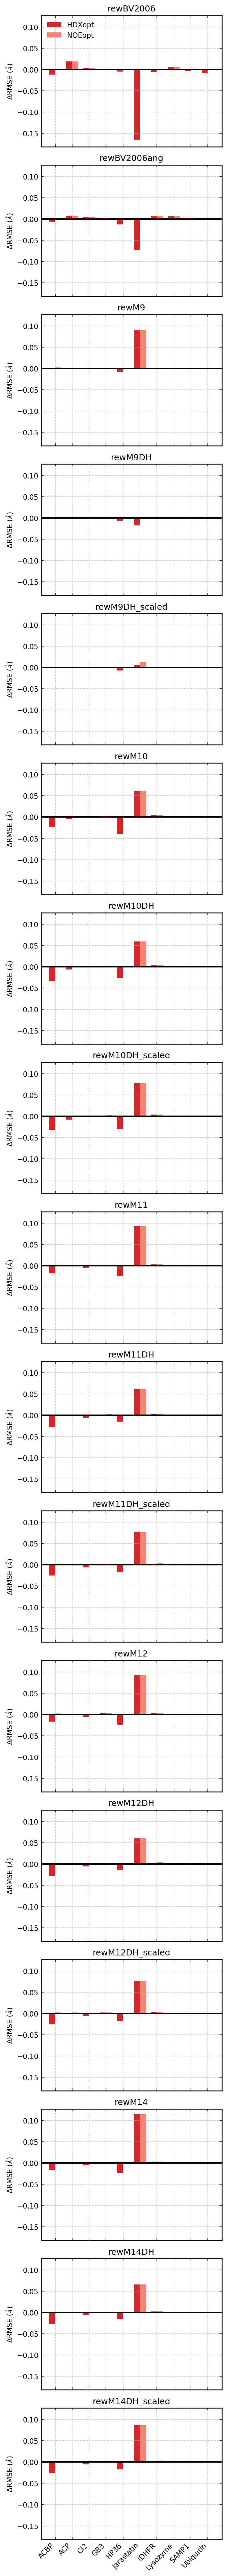

In [4]:


# ---- Compute ΔRMSE FOR EACH PROTEIN × MODEL ----
rows = []

for model in models:
    for protein in proteins:

        dat = pd.read_csv(outpath + f'{protein}_{model}_NOE_validation.csv')

        prior = list(dat['NOE_RMSE'])[0]
        post1 = list(dat['NOE_RMSE'])[-1]
        post2 = np.min(dat['NOE_RMSE'])

        delta_HDXopt = prior - post1
        delta_NOEopt = prior - post2

        rows.append({
            "Model": model,
            "Protein": protein,
            "HDXopt": delta_HDXopt,
            "NOEopt": delta_NOEopt
        })

df = pd.DataFrame(rows)


# ---- PLOTTING ----
n_models = len(models)
x = np.arange(len(proteins))
width = 0.35

fig, axes = plt.subplots(
    n_models, 1,
    figsize=(4.5, 3 * n_models),
    sharex=True, sharey=True
)

if n_models == 1:
    axes = [axes]  # make iterable if only one model

# global y-limits
ymin = df[["HDXopt", "NOEopt"]].min().min() * 1.1
ymax = df[["HDXopt", "NOEopt"]].max().max() * 1.1

for idx, model in enumerate(models):
    ax = axes[idx]
    sub = df[df["Model"] == model]

    ax.bar(x - width/2, sub["HDXopt"], width, label="HDXopt", color="tab:red")
    ax.bar(x + width/2, sub["NOEopt"], width, label="NOEopt", color="salmon")

    ax.axhline(0, color="black")
    ax.set_ylim(ymin, ymax)
    ax.set_title(model)
    ax.set_ylabel("ΔRMSE ($\\AA$)")

    if idx == 0:
        ax.legend(loc="upper left")

axes[-1].set_xticks(x)
axes[-1].set_xticklabels(proteins, rotation=45, ha='right')

plt.tight_layout()
plt.savefig(outpath + "NOE_validation_per_protein_per_model.png", dpi=300)

